In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
dfield_approach_elastix_path = os.path.abspath(os.path.join(current_path, '../'))
sys.path.append(base_path)
sys.path.append(dfield_approach_elastix_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import constants as cts
import dfield_applier as dfield_applier
import utils.util_freesurfer_segmentation as util_freesurfer

np.set_printoptions(precision=4)



In [2]:

def get_img_all_data_you_need(id, simple_mask=True):
    img_moving_path_name = pil.get_registered_to_template_image_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True)
    mask_moving_path_name = pil.get_segmentation_path_name(3, id, simple=simple_mask, absolute=True)

    dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)

    # load images and masks
    img_moving, aff_moving = nfc.load_nifti(img_moving_path_name)
    mask_moving, _ = nfc.load_nifti(mask_moving_path_name)

    img_fixed, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
    mask_fixed, _ = nfc.load_nifti(pil.get_segmentation_path_name(4, id, simple=simple_mask, absolute=True))

    img_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_REGISTERED))
    if simple_mask:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_SIMPLE_REGISTERED))
    else:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_REGISTERED))

    img_moving = util.skull_stripping_and_normalize(img_moving, mask_moving) 
    img_fixed = util.skull_stripping_and_normalize(img_fixed, mask_fixed) 
    img_registed = util.skull_stripping_and_normalize(img_registed, mask_registed)

    metrisc_original = util.get_metrics_dict(img_moving, img_fixed)
    metrisc_expected = util.get_metrics_dict(img_registed, img_fixed)

    dice_original = util.compute_multiple_dice_coefficients(mask_moving, mask_fixed)
    dice_expected = util.compute_multiple_dice_coefficients(mask_registed, mask_fixed)

    metrics_list = [metrisc_original, metrisc_expected]
    dices_list = [dice_original, dice_expected]


    return  (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving


### Compute metrics

In [3]:
matchin_ids = pil.get_matching_ids()
# id_indexs = [301,302,303,304,305,306,307]
# id_indexs = [301,302,303,304,305]
# id_indexs = [0, 11, 101, 301,302,303,304]
id_indexs = [302]

valid_mean_dfields = [10, 100]

# valid_mean_dfields = [100]
# patch_shapes = [16]
# sim_metrics=['dice']


# sim_metrics=['ssim','dice']

# df_first_columns = list(('ORG', 'EXP') + tuple(["{0:03}_{1}_{2}".format(a,b,c) for a,b,c in zip(valid_mean_dfields, patch_shapes, sim_metrics)]))
imgs_list = []
ordered_index_imgs = []
ordered_index_segs = []

df_first_columns_list = []

for id_index in id_indexs:
# for id_index in [id_indexs[1]]:
    df_first_columns = ['ORG', 'EXP']
    
    id_traget = matchin_ids[id_index]
    print(f"ID: {id_index}: {matchin_ids[id_index]}")
    (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving = get_img_all_data_you_need(id_traget, simple_mask=False)
    
    imgs = [(img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)]
    for valid_mean_dfield in valid_mean_dfields:
        for nb_tissues in ["MT36", "MT96", 36, 96]:
        # for nb_tissues in ["MT36"]:

            mean_dfield_path_name = cts.get_tissue_based_dfield_path_name(id_traget, nb_tissues, cts.PFILE_0038, valid_mean_dfield)

            if fc.verify_file(mean_dfield_path_name):
                
                _img_reg = dfield_applier.apply_deformation_field_elastix(img_moving_path_name, mean_dfield_path_name)
                _mask_reg = dfield_applier.apply_deformation_field_elastix(mask_moving_path_name, mean_dfield_path_name, binary=True)
                _img_reg_to_save = _img_reg.copy()

                _img_reg = util.skull_stripping_and_normalize(_img_reg, _mask_reg)

                metrics_list.append(util.get_metrics_dict(_img_reg, img_fixed))
                dices_list.append(util.compute_multiple_dice_coefficients(_mask_reg, mask_fixed))

                imgs.append((_img_reg, _mask_reg))
                df_first_columns.append("{0:03}, {1}".format(valid_mean_dfield, nb_tissues))

                # save images
                dir_name = os.path.dirname(mean_dfield_path_name) + '/imgs_results'
                reg_img_path_name = f"{dir_name}/{id_traget}_T{nb_tissues}_REG_T1_{valid_mean_dfield}.nii.gz"
                reg_seg_path_name = f"{dir_name}/{id_traget}_T{nb_tissues}_REG_SEG_{valid_mean_dfield}.nii.gz"
                nfc.save_nifti(_img_reg_to_save, aff_moving, reg_img_path_name)
                nfc.save_nifti(_mask_reg, aff_moving, reg_seg_path_name)


    imgs_list.append(imgs)
    df_first_columns_list.append(df_first_columns)

    df_metrics = pd.DataFrame(metrics_list)
    df_metrics.insert(0, 'VALUES', df_first_columns)
    df_metrics = df_metrics.sort_values(by=df_metrics.columns[-1], ascending=False)
    display(df_metrics.head(10))

    ordered_index_img = df_metrics.index.to_list()
    ordered_index_img = [idx for idx in ordered_index_img if idx != 0 and idx != 1]
    ordered_index_imgs.append(ordered_index_img)


    df_dices = pd.DataFrame(dices_list)
    df_dices_stats = pd.DataFrame({
        'min': df_dices.min(axis=1),
        'max': df_dices.max(axis=1),
        'mean': df_dices.mean(axis=1)
    })
    df_dices_stats.insert(0, 'VALUES', df_first_columns)
    df_dices_stats = df_dices_stats.sort_values(by=df_dices_stats.columns[-1], ascending=False)

    ordered_index_seg = df_dices_stats.index.to_list()
    ordered_index_seg = [idx for idx in ordered_index_seg if idx != 0 and idx != 1]
    ordered_index_segs.append(ordered_index_seg)
    


    
    display(df_dices_stats.head(10))
    



ID: 302: 08202


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000028,0.985230,0.841844,0.974578
7,"100, MT96",0.000045,0.953048,0.738476,0.963742
6,"100, MT36",0.000045,0.952639,0.738311,0.963555
8,"100, 36",0.000045,0.951771,0.738371,0.963543
9,"100, 96",0.000045,0.951486,0.737904,0.963493
3,"010, MT96",0.000047,0.948828,0.729869,0.961763
2,"010, MT36",0.000048,0.946461,0.724278,0.960919
5,"010, 96",0.000052,0.944173,0.722765,0.960378
4,"010, 36",0.000050,0.943747,0.721882,0.960321
0,ORG,0.000060,0.919692,0.698001,0.956920


,VALUES,min,max,mean
1,EXP,0.644751,0.994949,0.851748
6,"100, MT36",0.435758,0.993705,0.815893
8,"100, 36",0.422565,0.993723,0.815310
7,"100, MT96",0.435758,0.993730,0.814972
9,"100, 96",0.419693,0.993713,0.814543
3,"010, MT96",0.423792,0.993428,0.811113
2,"010, MT36",0.424078,0.993320,0.807485
4,"010, 36",0.433625,0.993304,0.806092
5,"010, 96",0.429769,0.993336,0.805282
0,ORG,0.077778,0.993248,0.796116


ID: 302: 08202


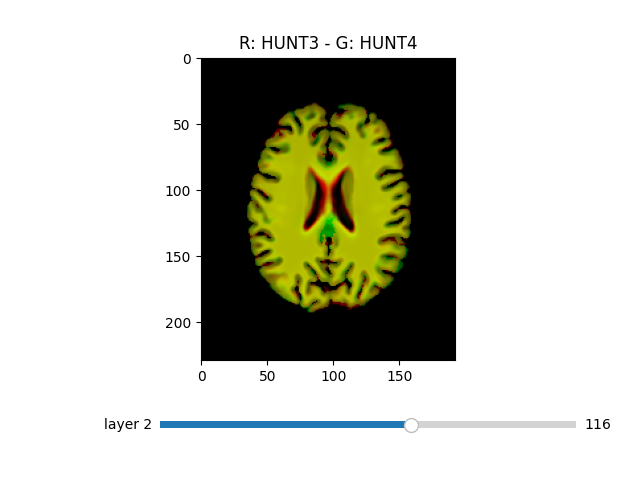

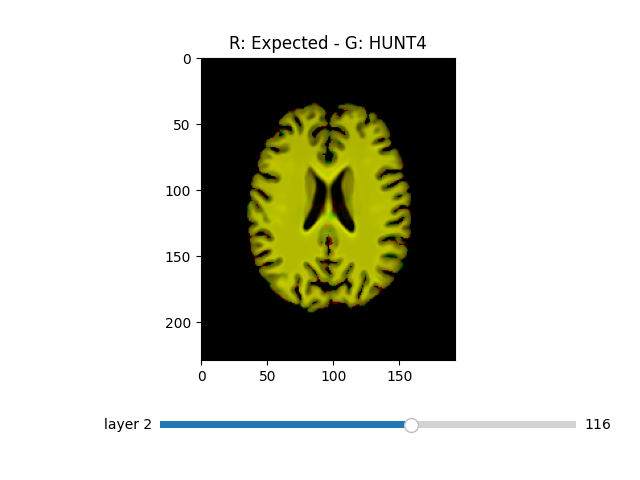

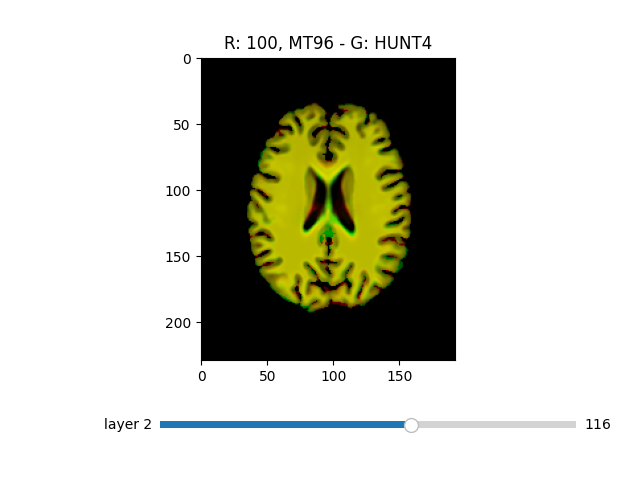

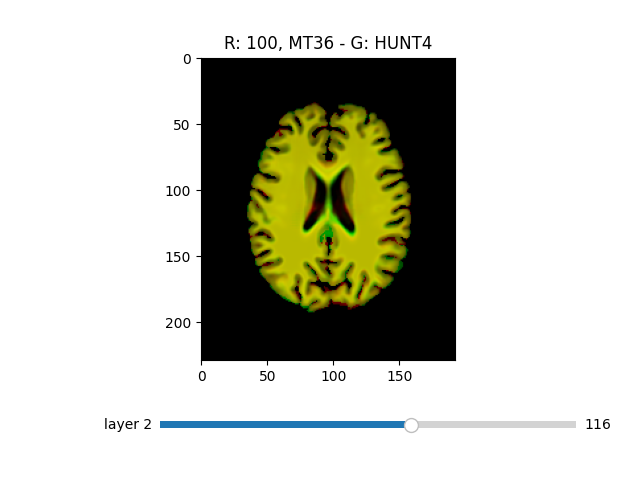

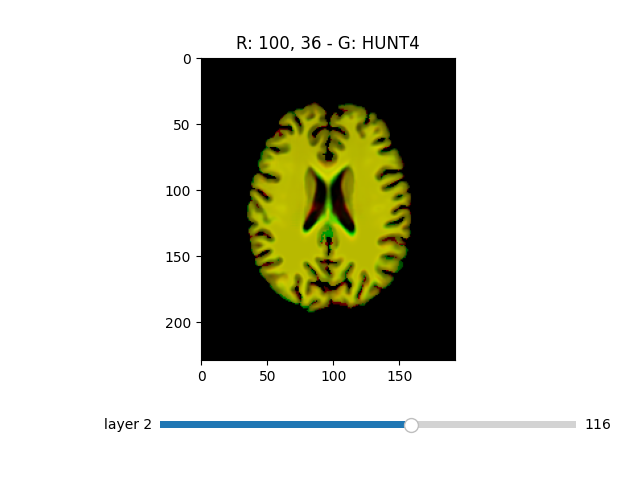

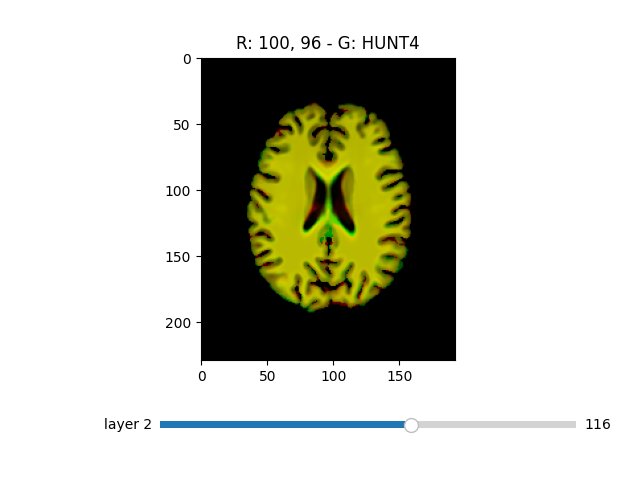

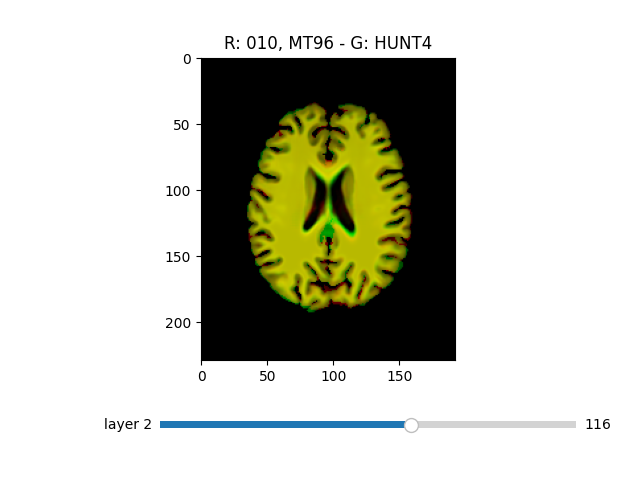

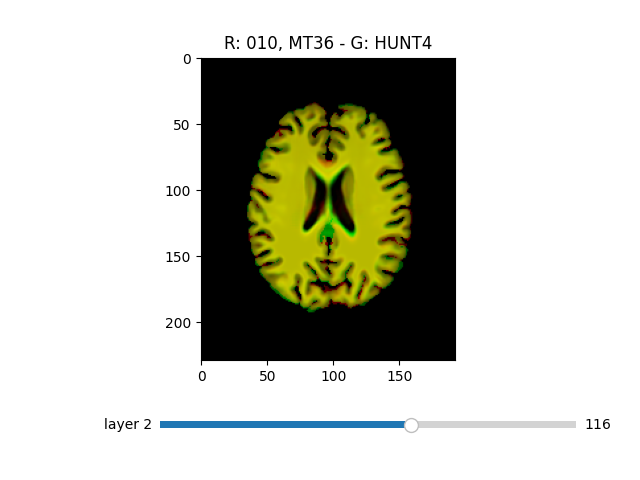

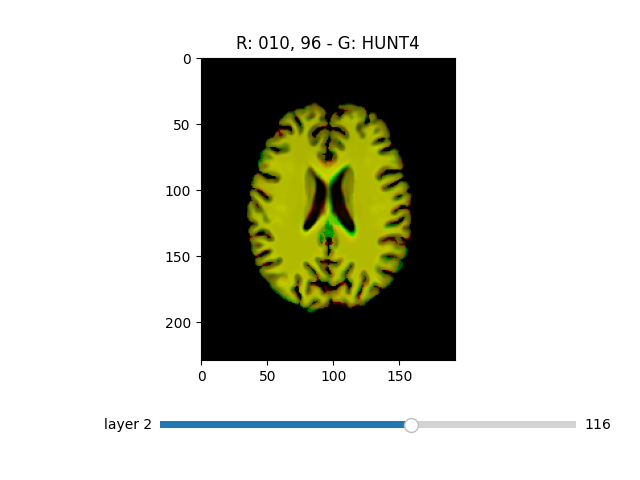

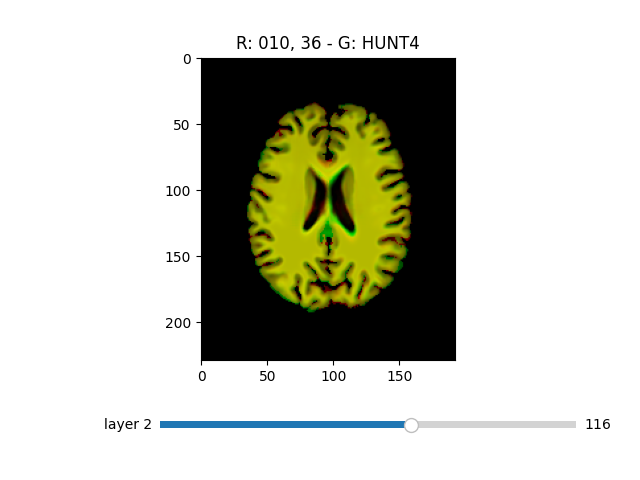

In [4]:
current_plane = 116

def shows_rgb_img(img_fixed, img_reg, name=""):
    img_rgb = np.stack((img_reg, img_fixed, np.zeros_like(img_fixed)), axis=3)
    fc.imgshow_3D(name, img_rgb, current_plane=current_plane, transpose=True, flip_ax=0)

%matplotlib widget
for id_index, imgs in enumerate(imgs_list):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    shows_rgb_img(img_fixed, img_moving, "R: HUNT3 - G: HUNT4")
    shows_rgb_img(img_fixed, img_expected, "R: Expected - G: HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    for i in ordered_index_imgs[id_index]:
        img, mask = imgs[i+1]
        shows_rgb_img(img_fixed, img, f"R: {df_first_columns_list[id_index][i]} - G: HUNT4")

        # fc.imgshow_3D("BEST", img, current_plane=current_plane, transpose=True, flip_ax=0)

    # fc.imgshow_3D("HUNT3", img_moving, current_plane=current_plane, transpose=True, flip_ax=0)
    # fc.imgshow_3D("HUNT4", img_fixed, current_plane=current_plane, transpose=True, flip_ax=0)

ID: 302: 08202


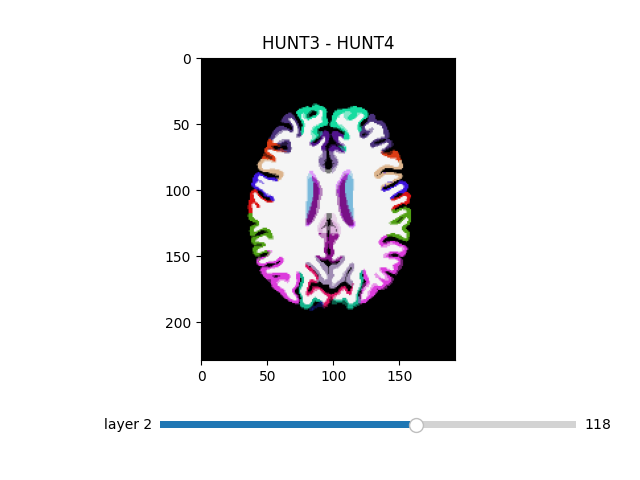

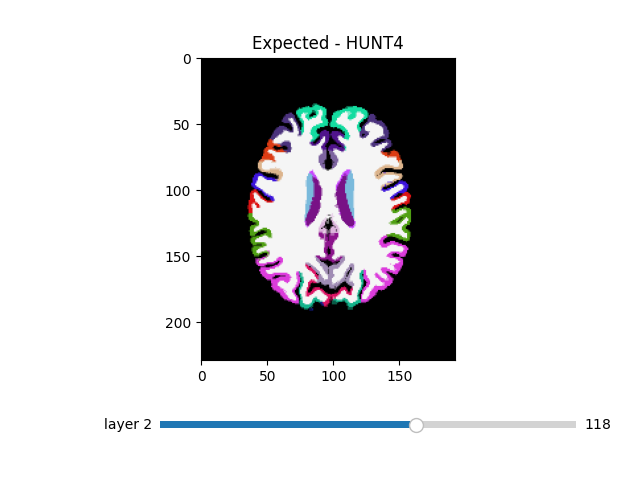

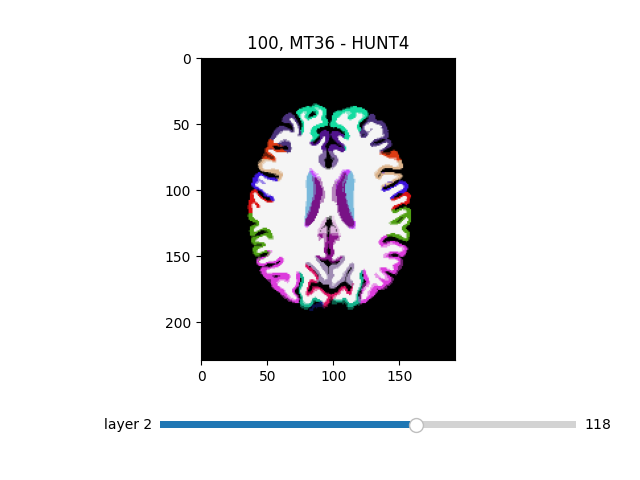

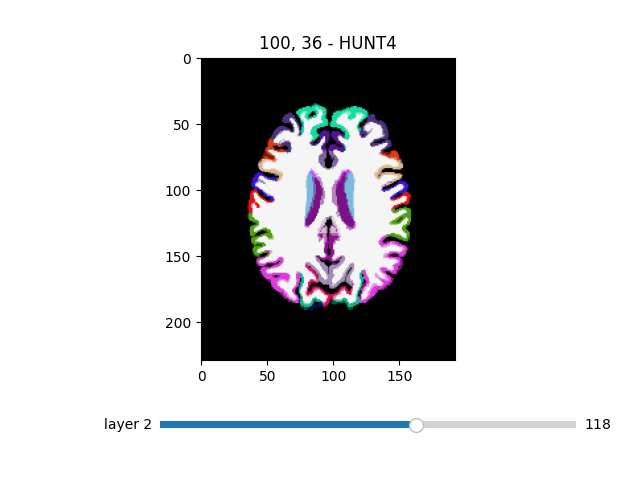

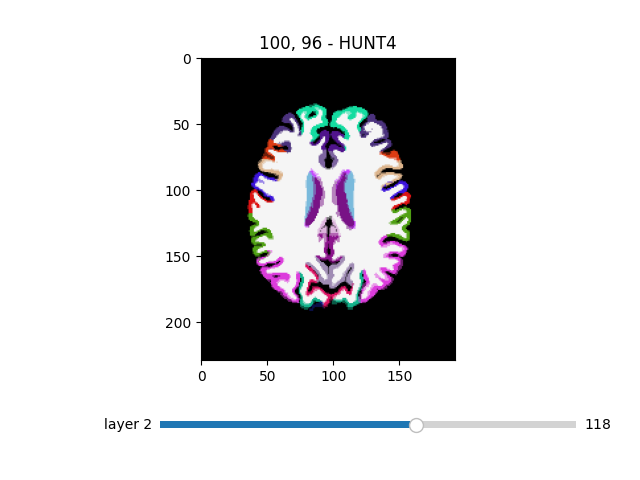

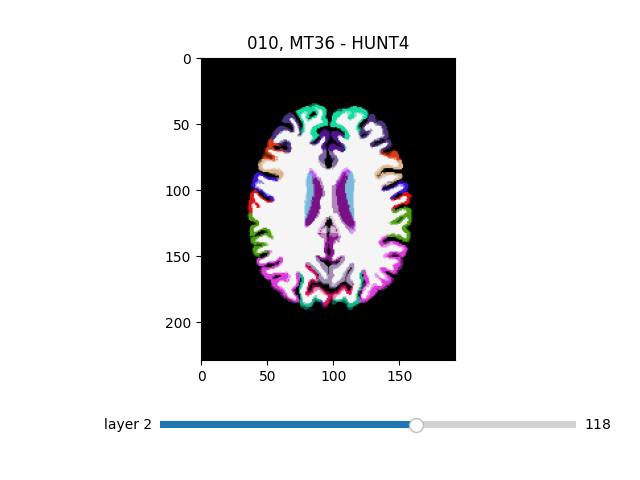

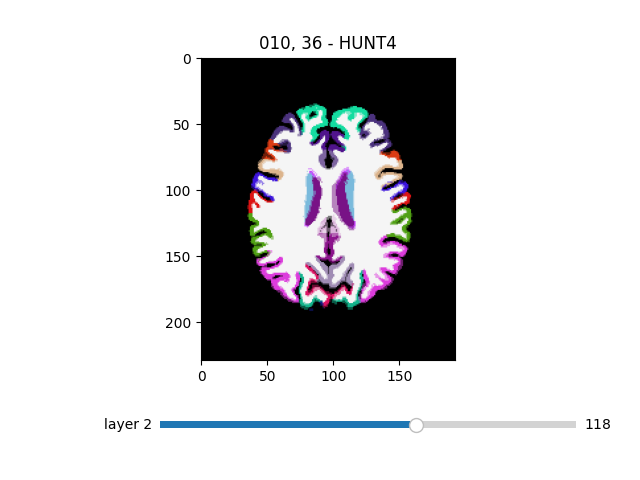

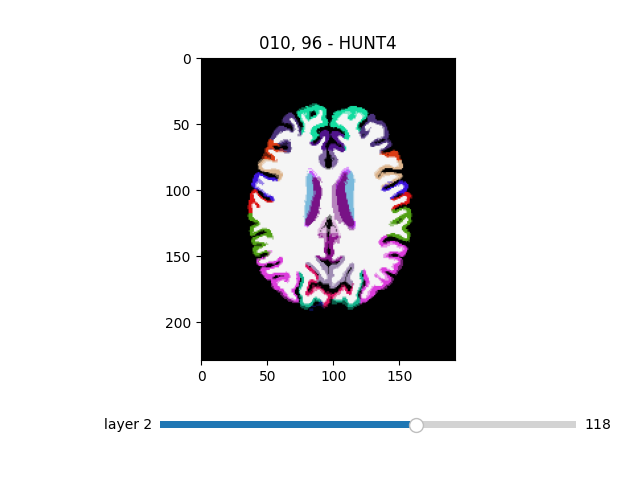

In [5]:
import utils.util_freesurfer_segmentation as util_freesurfer

def show_overlap_rgb_seg(seg_fixed, seg_reg, name=""):
    seg_fixed_rgb = util_freesurfer.seg_to_rgbseg(seg_fixed).astype(np.float32)
    seg_reg_rgb = util_freesurfer.seg_to_rgbseg(seg_reg).astype(np.float32)

    overlap_original = ((seg_fixed_rgb + seg_reg_rgb) / 2).astype(np.uint8)
    fc.imgshow_3D(name, overlap_original, current_plane=118, transpose=True, flip_ax=0)


%matplotlib widget
for id_index, imgs in enumerate(imgs_list):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    show_overlap_rgb_seg(mask_fixed, mask_moving, "HUNT3 - HUNT4")
    show_overlap_rgb_seg(mask_fixed, mask_expected, "Expected - HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    # for i in [ordered_index_seg[id_index][0]]:
    for i in ordered_index_segs[id_index]:

        img, mask = imgs[i+1]
        show_overlap_rgb_seg(mask_fixed, mask, f"{df_first_columns_list[id_index][i]} - HUNT4")



# Chat Analisis:

Certainly! Let's organize the results by registration method rather than by individual metrics.

### Mean for Each Registration Method:

#### EXP:
- NCC: 0.987
- SSIM: 0.969
- Min DICE: 0.595
- Max DICE: 0.994
- Mean DICE: 0.862

#### 010_16_dice:
- NCC: 0.936
- SSIM: 0.946
- Min DICE: 0.141
- Max DICE: 0.993
- Mean DICE: 0.797

#### 100_16_dice:
- NCC: 0.942
- SSIM: 0.947
- Min DICE: 0.157
- Max DICE: 0.993
- Mean DICE: 0.800

#### 010_32_dice:
- NCC: 0.935
- SSIM: 0.946
- Min DICE: 0.133
- Max DICE: 0.993
- Mean DICE: 0.796

#### 100_32_dice:
- NCC: 0.941
- SSIM: 0.946
- Min DICE: 0.148
- Max DICE: 0.993
- Mean DICE: 0.798

#### 010_16_ssim:
- NCC: 0.941
- SSIM: 0.947
- Min DICE: 0.140
- Max DICE: 0.993
- Mean DICE: 0.799

#### 100_16_ssim:
- NCC: 0.941
- SSIM: 0.947
- Min DICE: 0.158
- Max DICE: 0.993
- Mean DICE: 0.800

#### 010_32_ssim:
- NCC: 0.936
- SSIM: 0.946
- Min DICE: 0.140
- Max DICE: 0.993
- Mean DICE: 0.797

#### 100_32_ssim:
- NCC: 0.933
- SSIM: 0.947
- Min DICE: 0.144
- Max DICE: 0.993
- Mean DICE: 0.798

#### ORG:
- NCC: 0.909
- SSIM: 0.941
- Min DICE: 0.166
- Max DICE: 0.993
- Mean DICE: 0.797

### Standard Deviation for Each Registration Method:

#### EXP:
- NCC: 0.000
- SSIM: 0.002
- Min DICE: 0.023
- Max DICE: 0.001
- Mean DICE: 0.005

#### 010_16_dice:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.036
- Max DICE: 0.000
- Mean DICE: 0.013

#### 100_16_dice:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.037
- Max DICE: 0.000
- Mean DICE: 0.007

#### 010_32_dice:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.035
- Max DICE: 0.000
- Mean DICE: 0.007

#### 100_32_dice:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.036
- Max DICE: 0.000
- Mean DICE: 0.007

#### 010_16_ssim:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.036
- Max DICE: 0.000
- Mean DICE: 0.007

#### 100_16_ssim:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.037
- Max DICE: 0.000
- Mean DICE: 0.007

#### 010_32_ssim:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.035
- Max DICE: 0.000
- Mean DICE: 0.007

#### 100_32_ssim:
- NCC: 0.000
- SSIM: 0.007
- Min DICE: 0.036
- Max DICE: 0.000
- Mean DICE: 0.007

#### ORG:
- NCC: 0.011
- SSIM: 0.009
- Min DICE: 0.039
- Max DICE: 0.000
- Mean DICE: 0.013

### Ranking of Registration Methods (Based on Mean and Standard Deviation):

1. EXP
2. 100_16_dice
3. 100_16_ssim
4. 100_32_ssim
5. 010_16_ssim
6. 010_32_ssim
7. 010_32_dice
8. 010_16_dice
9. 100_32_dice
10. ORG

This ranking considers both the mean and standard deviation across all metrics for each registration method. The lower the standard deviation and the higher the mean, the better the performance of the method.

# Chat comparation betwen similar images approach and patch base approach

I have to choose between two methods of registering medical images, the first one is using an approach with similar images and the second one is using an approach with similar patches, here I leave you the results of some metrics of the images after registering them (rms ncc mi ssim) and also of the segmentation register (min says, max says, mean says) tell me which of the two approaches is better:


### Approach 1: Similar Images

|   rms   |   ncc   |   mi    |   ssim   |
|---------|---------|---------|----------|
| 0.000043| 0.968373| 0.869161| 0.957996 |
| 0.000044| 0.954923| 0.740672| 0.963762 |
| 0.000052| 0.939306| 0.906101| 0.941883 |
| 0.000049| 0.957999| 0.761985| 0.957639 |
| 0.000062| 0.912017| 0.838258| 0.934305 |
| 0.000056| 0.941385| 0.832450| 0.946594 |
| 0.000048| 0.951069| 0.827049| 0.951132 |

|   min   |   max   |   mean   |
|---------|---------|----------|
| 0.426008| 0.992578| 0.830862 |
| 0.510434| 0.993746| 0.818144 |
| 0.266984| 0.989794| 0.792260 |
| 0.526404| 0.992883| 0.818358 |
| 0.254077| 0.989237| 0.777818 |
| 0.253582| 0.990896| 0.796123 |
| 0.392628| 0.991477| 0.814517 |

### Approach 2: Similar Patches

|   rms   |   ncc   |   mi    |   ssim   |
|---------|---------|---------|----------|
| 0.000043| 0.967811| 0.867086| 0.957470 |
| 0.000045| 0.952217| 0.740465| 0.963672 |
| 0.000053| 0.939881| 0.901370| 0.940798 |
| 0.000044| 0.961926| 0.763336| 0.958282 |
| 0.000063| 0.911139| 0.838595| 0.934821 |
| 0.000057| 0.942384| 0.834770| 0.947179 |
| 0.000049| 0.959526| 0.834778| 0.952276 |

|   min   |   max   |   mean   |
|---------|---------|----------|
| 0.401559| 0.992521| 0.830761 |
| 0.406025| 0.993714| 0.814361 |
| 0.227382| 0.989572| 0.789768 |
| 0.563530| 0.992896| 0.819596 |
| 0.255196| 0.989411| 0.779463 |
| 0.305514| 0.990985| 0.800276 |
| 0.418052| 0.991621| 0.814885 |



## Chat response

To determine which approach is better, it's important to analyze the provided metrics for each of them. The metrics provided are RMS (Root Mean Square), NCC (Normalized Cross-Correlation), MI (Mutual Information), SSIM (Structural Similarity Index), and then segmentation-specific metrics like the Dice coefficient.

Here's a comparative analysis between both approaches based on the provided metrics:

### Approach 1: Similar Images
- **RMS:** Values range from 0.000043 to 0.000062.
- **NCC:** Values are high, ranging from 0.912 to 0.968.
- **MI:** Values are relatively high, ranging from 0.740 to 0.906.
- **SSIM:** Values are high, ranging from 0.934 to 0.963.
- **Dice Coefficient:** The Dice coefficient ranges from a minimum of 0.254 to a maximum of 0.526, with an average of 0.777 to 0.830.

### Approach 2: Similar Patches
- **RMS:** Values are similar to Approach 1, ranging from 0.000043 to 0.000063.
- **NCC:** Similar to Approach 1, ranging from 0.911 to 0.967.
- **MI:** Similar to Approach 1, ranging from 0.740 to 0.901.
- **SSIM:** Similar to Approach 1, ranging from 0.934 to 0.963.
- **Dice Coefficient:** The Dice coefficient ranges from a minimum of 0.227 to a maximum of 0.563, with an average of 0.779 to 0.830.

### Analysis:
- Both approaches show similar values in terms of RMS, NCC, MI, and SSIM.
- The Dice coefficient, which evaluates segmentation, also shows comparable results between the two approaches.
- There's no significant difference in metrics between the two approaches.

### Conclusion:
Since the metrics are similar in both approaches, there's no clear winner in terms of performance. Both approaches seem equally effective for medical image registration and segmentation. The choice between them could depend on other factors such as computational complexity or ease of implementation. It would be advisable to consider other criteria besides these metrics to make a final decision.